# Feature selection

Understanding the relationships among variables is critical for forecasting tasks, as the target variable might be influenced by multiple independent variables acting as predictors. Multivariate analysis was conducted to understand how variables interact and collectively influence the target featur. By examining relationships among multiple features, it was possible to identify relevant predictors, detect redundancy, and guide feature selection for forecasting models. 

This study applyied a hybrid feature selection,  where both **Pearson’s correlation coefficient** and **Spearman’s rank correlation coefficient** were computed. Pearson’s method measures linear relationships, while Spearman’s method captures monotonic but potentially non-linear dependencies. To complement the numerical analysis, a **correlation heatmap**, **pair plot**, and **scatter plot** were used to visually represent the strength of relationships across variables. Additionaly, **Random forest algorithm** was used as machine learning method for ranking the feature importance.

### Libraries

In [23]:
#Data manipulation
import pandas as pd
import numpy as np
# Plots
import matplotlib.pyplot as plt
import seaborn as sns
#random forest
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor



In [7]:
df=pd.read_csv('dbulin 2015-01-01 to 2024-12-31.csv',parse_dates=["datetime"])
df.head()

,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,precip,...,solarenergy,uvindex,sunrise,sunset,moonphase,conditions,description,icon,stations,doy
0,2015-01-01,13.6,7.9,11.3,13.6,2.8,10.5,8.4,82.9,4.786,...,0.8,1,2015-01-01T08:40:25,2015-01-01T16:16:46,0.37,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME",1
1,2015-01-02,7.0,3.6,5.3,2.0,-2.0,0.4,0.8,73.1,0.451,...,3.5,2,2015-01-02T08:40:15,2015-01-02T16:17:53,0.40,"Rain, Partially cloudy",Becoming cloudy in the afternoon with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME",2
2,2015-01-03,6.1,-1.2,3.0,4.0,-4.5,0.2,2.1,93.9,7.283,...,1.4,1,2015-01-03T08:40:01,2015-01-03T16:19:03,0.44,"Rain, Partially cloudy",Partly cloudy throughout the day with rain or ...,snow,"03971099999,EIDW,03969099999,03967099999,EIME",3
3,2015-01-04,6.8,-1.6,2.6,5.0,-5.7,0.5,1.6,93.5,0.000,...,1.6,1,2015-01-04T08:39:43,2015-01-04T16:20:16,0.48,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"03971099999,EIDW,03969099999,03967099999,EIME",4
4,2015-01-05,10.7,2.9,8.9,10.7,1.6,7.3,7.1,88.6,0.026,...,0.9,1,2015-01-05T08:39:23,2015-01-05T16:21:32,0.50,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"03971099999,EIDW,03969099999,03967099999,EIME",5


### Correlation Matrix

A correlation matrix is a table that displays the correlation coefficients between multiple variables, showing how strongly pairs of variables are related. Each cell in the matrix contains a value ranging from -1 to +1, where -1 indicates a perfect negative correlation, +1 indicates a perfect positive correlation, and 0 indicates no correlation.

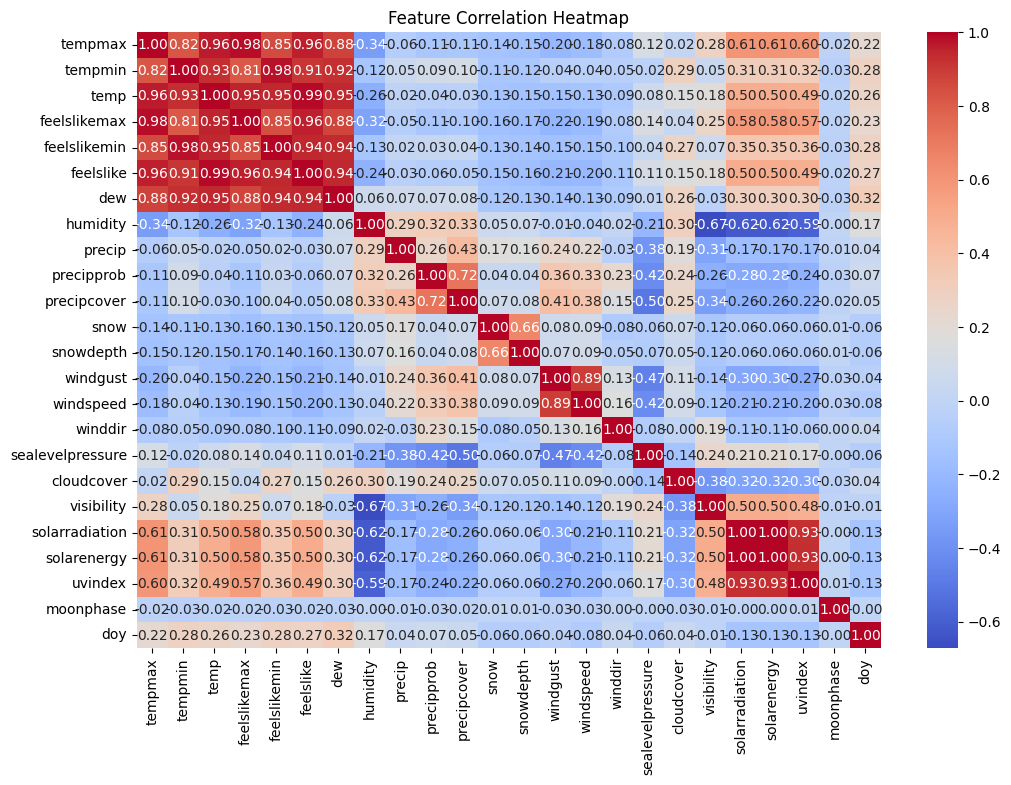

In [8]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Feature Correlation Heatmap')
plt.savefig('correlation', dpi=300)
plt.show()

Observations:

- Strongest Positive Correlations:
  solarenergy, uvindex, visibility, tempmax, tempmin, temp, feelslike,dew
- Strongest Negative Correlation:
  cloudcover, humidity, precip

### Pearson and Spearman Correlation

- **Pearson correlation coefficient (PCC)** is a correlation coefficient that measures linear correlation between two sets of data from -1 to 1.
- **Spearman's rank correlation** coefficient or Spearman's ρ is a number ranging from -1 to 1 that indicates how strongly two sets of ranks are correlated. 

In [10]:
# Linear correlation
pearson_correlation = df.select_dtypes(include='number').corr()['solarradiation']
numerical_col = df.select_dtypes(include='number')

# Nonlinear correlation
spearman_corr = numerical_col.corr(method='spearman')['solarradiation']
#print("Pearson correlation:", pearson_correlation)
#print("Spearman correlation:", spearman_corr)

In [11]:
# Combine into a dataframe
corr_df = pd.concat([pearson_correlation.rename('Pearson'), spearman_corr.rename('Spearman')], axis=1)
corr_df

,Pearson,Spearman
tempmax,0.605832,0.631947
tempmin,0.312550,0.350554
temp,0.495255,0.519345
feelslikemax,0.582393,0.627436
feelslikemin,0.354524,0.389414
feelslike,0.497682,0.524569
dew,0.298002,0.333118
humidity,-0.619252,-0.618116
precip,-0.169125,-0.257288
precipprob,-0.284800,-0.255932


<Figure size 1200x500 with 0 Axes>

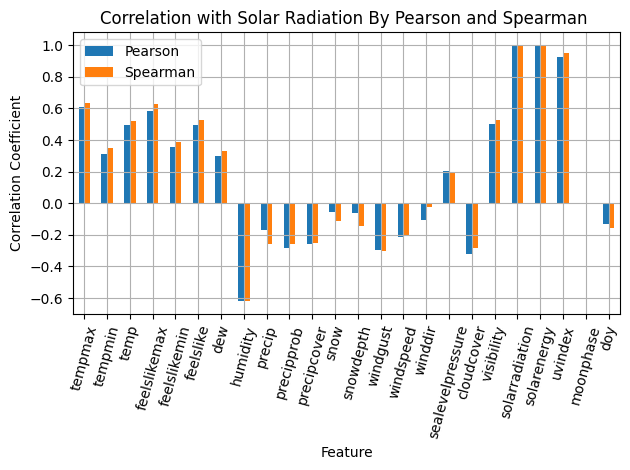

In [12]:
# Plot
plt.figure(figsize=(12, 5))
corr_df.plot(kind='bar')
plt.title('Correlation with Solar Radiation By Pearson and Spearman ')
plt.xlabel('Feature')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=75)
plt.grid()
plt.tight_layout()
plt.savefig('pearson_spearman_correlation', dpi=300)
plt.show()

Observations:
- solarradiation, solarenergy, uvindex, show strong corrrelation ( here could be a leakage data risk).
- temperature indications inclding feelslike have a strong correlation
- humidity shows strong negative correlation.

## Random Forest for Feature selection

Random Forest algorithm that can be effectively used for feature selection by ranking the importance of different features in a dataset. It evaluates feature importance using metrics like Gini importance, allowing you to identify and retain the most relevant features while discarding less useful ones.

In [15]:
## feature processing
#numerical columns
numerical_col = df.select_dtypes(include='number')
#target variable
y = df['solarradiation']
# the rest of the features (dropong solarenergy and uvindex to prevent of leakage)
X = numerical_col.drop(columns=['solarradiation','solarenergy', 'uvindex','doy','moonphase'])


**TimeSeriesSplit** is a cross-validation technique designed for time series data. It splits the data into train and test sets while preserving the temporal order, which is crucial for evaluating machine learning models on time series problems.

In [18]:
# Time-series split to avoid leakage
tscv = TimeSeriesSplit(n_splits=5)

In [21]:
# Container for feature importances
# it starts with zeros
importan = np.zeros(X.shape[1])

In [24]:
## train and fit function
for train, test in tscv.split(X):
    X_train, y_train = X.iloc[train], y.iloc[train]
    model = RandomForestRegressor(
        n_estimators=300, 
        max_depth=10, 
        random_state=0, 
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    importan += model.feature_importances_ #save tge scores in the container

In [25]:
# get the average from folds
importan /= tscv.get_n_splits()

In [26]:
# feature important dataframe
feature_important = pd.Series(importan, index=X.columns).sort_values(ascending=False)

In [27]:
feature_important

humidity            0.338482
tempmax             0.153482
feelslikemax        0.147291
winddir             0.072365
windgust            0.061209
cloudcover          0.060063
visibility          0.049362
windspeed           0.022993
sealevelpressure    0.018518
precip              0.017835
feelslike           0.012022
feelslikemin        0.011195
tempmin             0.011108
dew                 0.010150
temp                0.006981
precipcover         0.005625
precipprob          0.000780
snowdepth           0.000492
snow                0.000046
dtype: float64

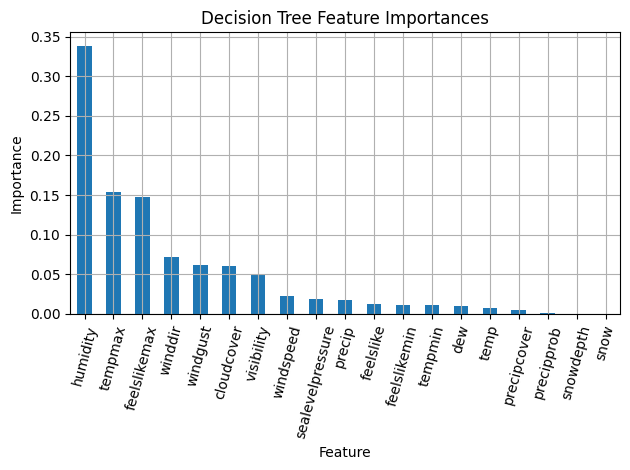

In [28]:
#plot
feature_important.plot(kind='bar')
plt.title('Decision Tree Feature Importances')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=75)
plt.grid()
plt.tight_layout()
plt.savefig('decision_tree_feature_importances', dpi=300)
plt.show()

Observations:
- humidity and tempmax have a strong importance
- cloudcover, visibility, winddir, windgust moderate importance

### Feature Selection Conclution

After Pearson, Spearman, Correlation heatmap, and Random Forest analyses, the most consitent feature predictors for solar radiation are humidity, tempmax, cloudcover, visibility, winddir, and windgust. Variables feelslike, temp, and tempmax have similar effects, however tempmax showed more reletance, for this reason only tempmax is been kept. In order to prevent data leakage, solarenergy and uvindex must be removed

The feature selecction above captures and identify the input features that contribute most to an accurate solar radiation prediction.

### Dataset with only retative features

In [29]:
df.columns

Index(['datetime', 'tempmax', 'tempmin', 'temp', 'feelslikemax',
       'feelslikemin', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob',
       'precipcover', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir',
       'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation',
       'solarenergy', 'uvindex', 'sunrise', 'sunset', 'moonphase',
       'conditions', 'description', 'icon', 'stations', 'doy'],
      dtype='object')

In [30]:
#erasing non-relative features 
df=df.drop(['precipprob','tempmin','temp','feelslikemin', 'feelslike','feelslikemax', 'dew','precipcover', 'snow', 'snowdepth', 'sunrise', 'sunset', 'moonphase','conditions','solarenergy', 'uvindex', 'description', 'icon', 'stations'],axis=1)

In [37]:
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
0,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
1,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
3,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
4,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


In [36]:
# Save DataFrame as a CSV
df.to_csv("dublin_2015_to_2024_selected.csv", index=False)